In [1]:
%matplotlib inline
import pandas as pd
import matplotlib.pyplot as plt
from importlib import reload
import keras
import visualkeras
import tensorflow as tf

from modules import data_preprocessing as dataPrep
from modules import plotting_functions as plf
from modules import model_functions as mod

2026-09-14 14:55:52.213333: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
model = mod.build_model([36,60,60,3], 'anisotropic_reg_2_23_MaxPooling')
model.summary()

Building model using architecture: anisotropic_reg_2_23_MaxPooling


I0000 00:00:1789390555.108399   86746 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5478 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 2060 SUPER, pci bus id: 0000:09:00.0, compute capability: 7.5


Model: "RPN_classification_model_anisotropic_regularized_2_23_MaxPooling"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv3d (Conv3D)                 │ (None, 36, 60, 60, 32) │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 36, 60, 60, 32) │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d (MaxPooling3D)    │ (None, 36, 30, 30, 32) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_1 (Conv3D)               │ (None, 36, 30, 30, 64) │        55,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 36, 30, 30, 64) │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout3d               │ (None, 36, 30, 30, 64) │             0 │
│ (SpatialDropout3D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d_1 (MaxPooling3D)  │ (None, 18, 15, 15, 64) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_2 (Conv3D)               │ (None, 18, 15, 15,     │       221,312 │
│                                 │ 128)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 18, 15, 15,     │           512 │
│ (BatchNormalization)            │ 128)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout3d_1             │ (None, 18, 15, 15,     │             0 │
│ (SpatialDropout3D)              │ 128)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d_2 (MaxPooling3D)  │ (None, 9, 7, 7, 128)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_3 (Conv3D)               │ (None, 9, 7, 7, 256)   │       884,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 9, 7, 7, 256)   │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout3d_2             │ (None, 9, 7, 7, 256)   │             0 │
│ (SpatialDropout3D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d_3 (MaxPooling3D)  │ (None, 4, 3, 3, 256)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3d_4 (Conv3D)               │ (None, 4, 3, 3, 512)   │     3,539,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 4, 3, 3, 512)   │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout3d_3             │ (None, 4, 3, 3, 512)   │             0 │
│ (SpatialDropout3D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling3d_4 (MaxPooling3D)  │ (None, 2, 1, 1, 512)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling3d            │ (None, 512)            │             

 Total params: 5,399,846 (20.60 MB)

 Trainable params: 5,397,862 (20.59 MB)

 Non-trainable params: 1,984 (7.75 KB)

/home/marcel/Repos/venv_default/lib/python3.12/site-packages/visualkeras/layered.py:231: UserWarning: The legend_text_spacing_offset parameter is deprecated and will be removed in a future release.
  warnings.warn("The legend_text_spacing_offset parameter is deprecated and will be removed in a future release.")


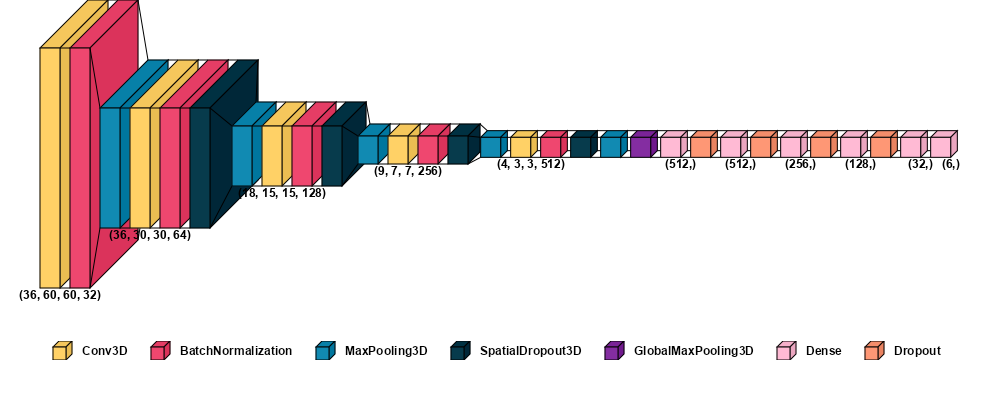

In [3]:
from tensorflow.keras.layers import Conv3D, Dense
from PIL import ImageFont
import visualkeras

# 1. Load a bold font (Adjust the filename based on your OS)
try:
    bold_font = ImageFont.truetype("arialbd.ttf", 12) 
except IOError:
    bold_font = ImageFont.load_default()

# 2. Update the custom text function
def layer_text(layer_index, layer):
    if isinstance(layer, (Conv3D, Dense)):
        # Remove the 'None' batch dimension
        shape_without_batch = layer.output_shape[1:]
        
        # Add spaces to shift text right
        shifted_text = "      " + str(shape_without_batch)
        
        return shifted_text, False
    
    return "", False

# 3. Apply Keras 3 compatibility patch
for layer in model.layers:
    if not hasattr(layer, 'output_shape'):
        layer.output_shape = layer.output.shape

# 4. Generate the visualization with padding
visualkeras.layered_view(
    model, 
    # to_file='model_architecture.png', 
    legend=True, 
    scale_xy=4,  
    scale_z=0.01,
    text_callable=layer_text,
    font=bold_font,
    padding=40  # Increases the outer margin to prevent text clipping (default is usually 10)
)

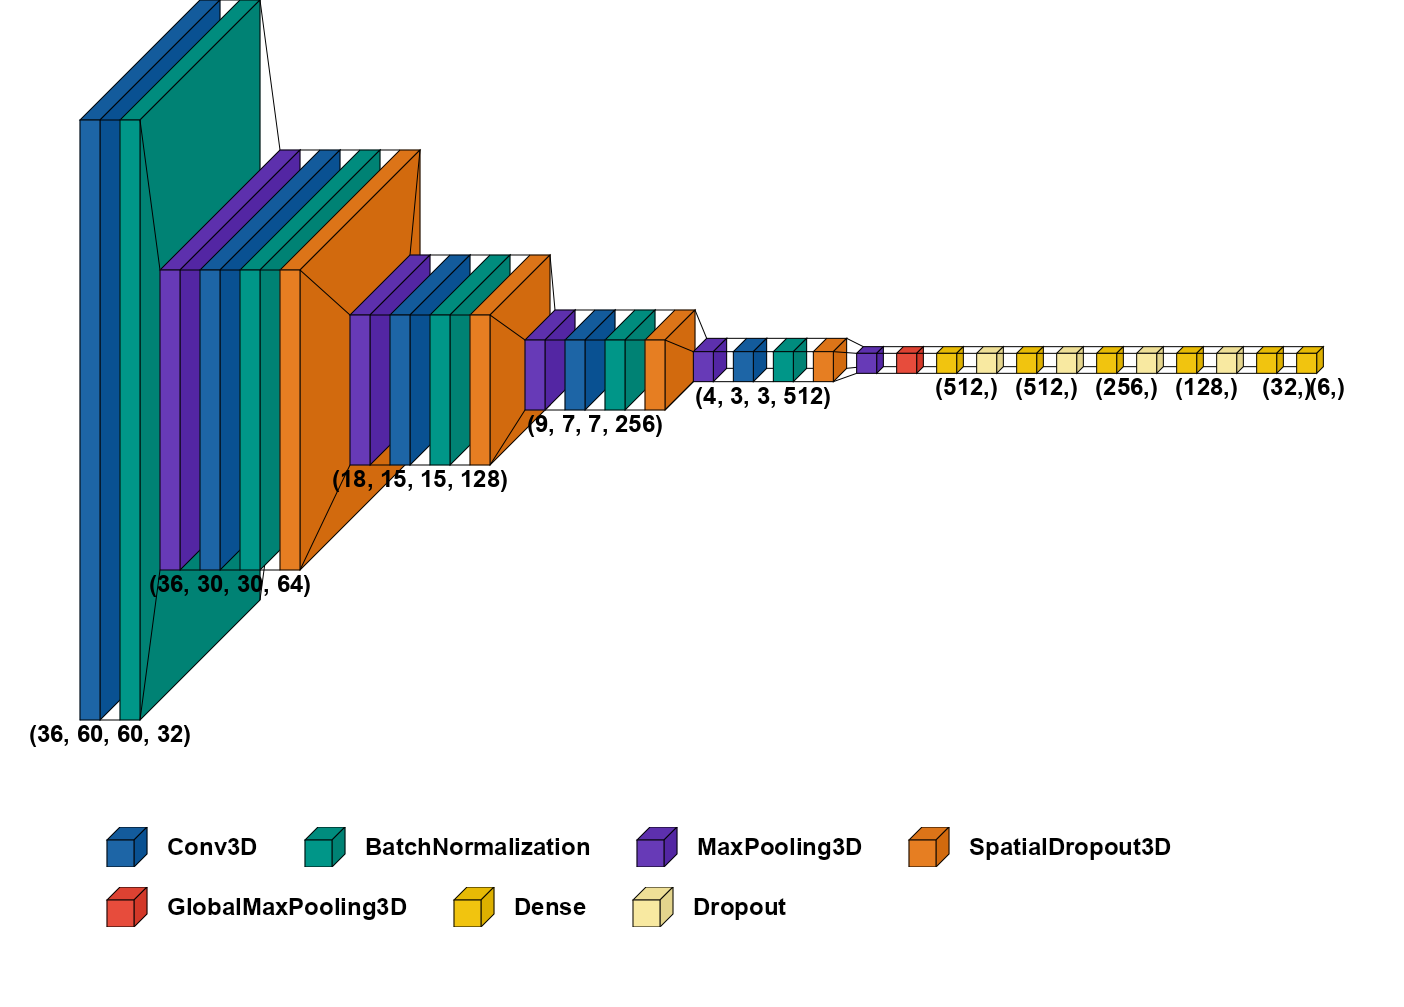

In [8]:
from tensorflow.keras.layers import Conv3D, Dense
from PIL import ImageFont
import visualkeras

# Define a multiplier to increase resolution (e.g., 2x, 3x, 4x)
res_factor = 2

# 1. Scale the font size up by the resolution factor
try:
    bold_font = ImageFont.truetype("arialbd.ttf", 12 * res_factor) 
except IOError:
    bold_font = ImageFont.load_default()

# 2. Update the custom text function (add more spaces to match the new scale)
def layer_text(layer_index, layer):
    if isinstance(layer, (Conv3D, Dense)):
        shape_without_batch = layer.output_shape[1:]
        # Multiply spaces by res_factor to keep the shift proportional
        shifted_text = (" " * 3 * res_factor) + str(shape_without_batch)
        return shifted_text, False
    return "", False

# 3. Apply Keras 3 compatibility patch
for layer in model.layers:
    if not hasattr(layer, 'output_shape'):
        layer.output_shape = layer.output.shape

from tensorflow.keras.layers import Conv3D, Dense, MaxPooling3D, BatchNormalization, SpatialDropout3D, GlobalMaxPooling3D, Dropout

custom_colors = {
    Conv3D: {'fill': '#1D65A6'},               # Rich Blue
    BatchNormalization: {'fill': '#009688'},   # Vibrant Teal
    MaxPooling3D: {'fill': '#673AB7'},         # Deep Purple
    SpatialDropout3D: {'fill': '#E67E22'},     # Warm Orange (steps smoothly into yellow)
    GlobalMaxPooling3D: {'fill': '#E74C3C'},   # Distinct Bright Red (Pops clearly)
    Dense: {'fill': '#F1C40F'},                # Bright Gold/Yellow
    Dropout: {'fill': '#F8E9A1'}               # Light Lemon
}

# 4. Generate the visualization with scaled parameters
visualkeras.layered_view(
    model, 
    to_file='model_architecture_high_res.png', 
    legend=True,
    color_map=custom_colors,
    scale_xy=5 * res_factor,       # Multiply spatial scaling
    scale_z=0.005 * res_factor,     # Multiply depth scaling
    padding=40 * res_factor,       # Multiply outer margin
    spacing=10 * res_factor,       # Scale gap between layers (default is 10)
    text_callable=layer_text,
    font=bold_font
)